# B0 — APTOS2019

Full fine-tuning with ordinary categorical CE and the deterministic official processor establishes the vanilla control.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

Exact recorded main training module matched by SHA-256 to [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/de4699e7162b461195f87924d5f7ca39d2313cdb/novelty/foundation_adaptation.py). The optional CLI uses the current [foundation adaptation](../../novelty/foundation_adaptation.py) for a separately recorded new run.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B0', 'APTOS2019'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '1e032de5154e6a0d9df90d93c8acfd10d7d74067ac8f444af8b0c43834835b80'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B0 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| implementation_sha256 | 289d50684fe9d8ca06c9237d5318ebc449346a6e51f75a659f3ecfcfc0e112b1 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": "none; deterministic official processor for train and validation"
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.816191 | — | — | — | — | — |
| 2 | 0.541868 | — | — | — | — | — |
| 3 | 0.457702 | — | — | — | — | — |
| 4 | 0.400188 | — | — | — | — | — |
| 5 | 0.35487 | — | — | — | — | — |
| 6 | 0.308571 | — | — | — | — | — |
| 7 | 0.263591 | — | — | — | — | — |
| 8 | 0.221405 | — | — | — | — | — |
| 9 | 0.178491 | — | — | — | — | — |
| 10 | 0.141205 | — | — | — | — | — |
| 11 | 0.110441 | — | — | — | — | — |
| 12 | 0.0838289 | — | — | — | — | — |
| 13 | 0.0638989 | — | — | — | — | — |
| 14 | 0.0521818 | — | — | — | — | — |
| 15 | 0.0445595 | — | — | — | — | — |
| 16 | 0.0399604 | — | — | — | — | — |
| 17 | 0.0374678 | — | — | — | — | — |
| 18 | 0.0365955 | — | — | — | — | — |
| 19 | 0.0409035 | — | — | — | — | — |
| 20 | 0.0415764 | — | — | — | — | — |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.624414 | 0.762295 | 0.431054 | 0.714578 | 0.789467 | 0.338798 |
| 2 | 0.562242 | 0.775956 | 0.46699 | 0.735495 | 0.816358 | 0.311475 |
| 3 | 0.518374 | 0.800546 | 0.577107 | 0.778927 | 0.865649 | 0.262295 |
| 4 | 0.501908 | 0.808743 | 0.623397 | 0.79945 | 0.867757 | 0.259563 |
| 5 | 0.512987 | 0.819672 | 0.637152 | 0.808121 | 0.881307 | 0.234973 |
| 6 | 0.499994 | 0.803279 | 0.606945 | 0.792036 | 0.880644 | 0.248634 |
| 7 | 0.510327 | 0.811475 | 0.652105 | 0.809628 | 0.886998 | 0.243169 |
| 8 | 0.511592 | 0.81694 | 0.648583 | 0.812251 | 0.888508 | 0.237705 |
| 9 | 0.5173 | 0.811475 | 0.659874 | 0.812507 | 0.888617 | 0.248634 |
| 10 | 0.541529 | 0.81694 | 0.65754 | 0.813817 | 0.87691 | 0.243169 |
| 11 | 0.576791 | 0.797814 | 0.651886 | 0.801517 | 0.878427 | 0.270492 |
| 12 | 0.599976 | 0.819672 | 0.664923 | 0.81895 | 0.888513 | 0.237705 |
| 13 | 0.64199 | 0.825137 | 0.665964 | 0.821613 | 0.89227 | 0.226776 |
| 14 | 0.643463 | 0.806011 | 0.640865 | 0.803815 | 0.87153 | 0.256831 |
| 15 | 0.68588 | 0.814208 | 0.66164 | 0.814432 | 0.887486 | 0.243169 |
| 16 | 0.816067 | 0.814208 | 0.650933 | 0.811894 | 0.886002 | 0.240437 |
| 17 | 0.78044 | 0.814208 | 0.673686 | 0.817133 | 0.88923 | 0.243169 |
| 18 | 0.789229 | 0.814208 | 0.654462 | 0.812975 | 0.888763 | 0.243169 |
| 19 | 0.82358 | 0.814208 | 0.658643 | 0.81292 | 0.874608 | 0.251366 |
| 20 | 0.865305 | 0.81694 | 0.665321 | 0.817833 | 0.89469 | 0.23224 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 272.083 | 33.8598 | — | — | 10.7688 | — | 2663383040 | — | 63 | 24 | 0 |
| 2 | 272.802 | 33.6392 | — | — | 10.7404 | — | 2663383040 | — | 54 | 28 | 3 |
| 3 | 274.093 | 33.541 | — | — | 10.6898 | — | 2663383040 | — | 41 | 32 | 2 |
| 4 | 271.504 | 33.1899 | — | — | 10.7917 | — | 2663383040 | — | 36 | 34 | 6 |
| 5 | 269.721 | 33.4542 | — | — | 10.8631 | — | 2663383040 | — | 40 | 26 | 13 |
| 6 | 273.15 | 33.6684 | — | — | 10.7267 | — | 2663383040 | — | 40 | 32 | 10 |
| 7 | 278.2 | 36.71 | — | — | 10.532 | — | 2663383040 | — | 36 | 33 | 16 |
| 8 | 335.008 | 34.0169 | — | — | 8.74606 | — | 2663383040 | — | 35 | 32 | 15 |
| 9 | 287.253 | 33.9109 | — | — | 10.2001 | — | 2663383040 | — | 30 | 39 | 15 |
| 10 | 310.191 | 42.2569 | — | — | 9.4458 | — | 2663383040 | — | 38 | 29 | 19 |
| 11 | 318.004 | 33.0791 | — | — | 9.21373 | — | 2663383040 | — | 34 | 40 | 24 |
| 12 | 268.655 | 33.2546 | — | — | 10.9062 | — | 2663383040 | — | 36 | 30 | 24 |
| 13 | 271.299 | 33.4605 | — | — | 10.7999 | — | 2663383040 | — | 39 | 25 | 24 |
| 14 | 274.034 | 33.6989 | — | — | 10.6921 | — | 2663383040 | — | 42 | 29 | 26 |
| 15 | 274.939 | 33.7994 | — | — | 10.6569 | — | 2663383040 | — | 35 | 33 | 26 |
| 16 | 275.645 | 33.5283 | — | — | 10.6296 | — | 2663383040 | — | 39 | 29 | 40 |
| 17 | 274.926 | 33.9866 | — | — | 10.6574 | — | 2663383040 | — | 34 | 34 | 35 |
| 18 | 271.945 | 32.8285 | — | — | 10.7742 | — | 2663383040 | — | 31 | 37 | 39 |
| 19 | 267.848 | 33.414 | — | — | 10.9391 | — | 2663383040 | — | 35 | 33 | 33 |
| 20 | 273.569 | 34.1586 | — | — | 10.7103 | — | 2663383040 | — | 35 | 32 | 38 |

## B0 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 17 | 0.814208 | 0.673686 | 0.817133 | 0.88923 | 0.243169 | 298 | 68 | 34 | 34 |

Frozen validation only. The selected checkpoint SHA-256 is `1e032de5154e6a0d9df90d93c8acfd10d7d74067ac8f444af8b0c43834835b80`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 174 | 6 | 0 | 0 | 0 |
| 1 | 1 | 23 | 11 | 0 | 0 |
| 2 | 0 | 15 | 76 | 3 | 7 |
| 3 | 0 | 0 | 3 | 10 | 7 |
| 4 | 0 | 2 | 10 | 3 | 15 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 96.6667 | 3.33333 | 0 | 0 | 0 |
| 1 | 2.85714 | 65.7143 | 31.4286 | 0 | 0 |
| 2 | 0 | 14.8515 | 75.2475 | 2.9703 | 6.93069 |
| 3 | 0 | 0 | 15 | 50 | 35 |
| 4 | 0 | 6.66667 | 33.3333 | 10 | 50 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994286 | 0.966667 | 0.980282 | 180 | 174 |
| 1 | 0.5 | 0.657143 | 0.567901 | 35 | 23 |
| 2 | 0.76 | 0.752475 | 0.756219 | 101 | 76 |
| 3 | 0.625 | 0.5 | 0.555556 | 20 | 10 |
| 4 | 0.517241 | 0.5 | 0.508475 | 30 | 15 |

Minority-grade predictions on the diagonal were grade 1 23/35, grade 3 10/20. The largest off-diagonal counts were 2 → 1 (15), 1 → 2 (11), 4 → 2 (10). The matrix gives 49 adjacent errors and 19 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B0_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B0_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

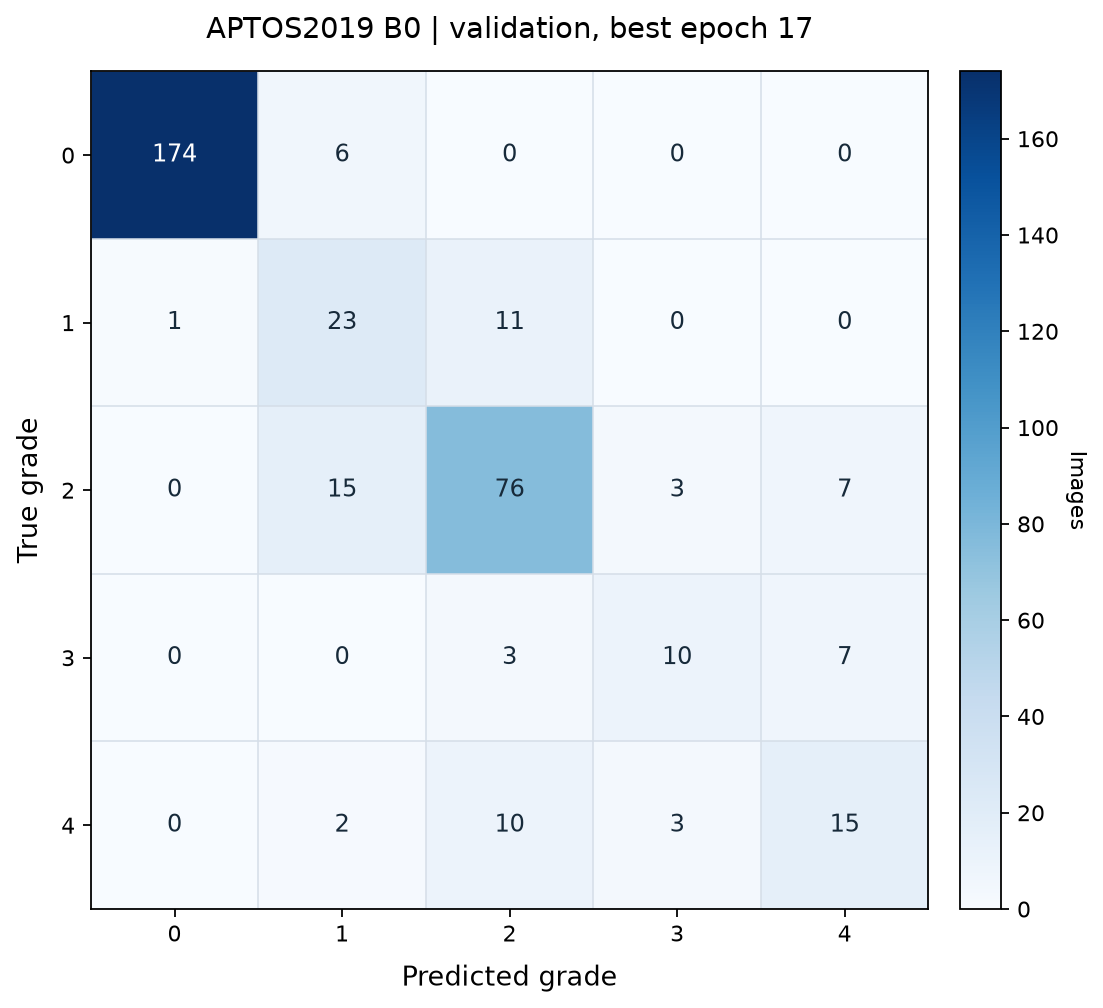

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B0_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

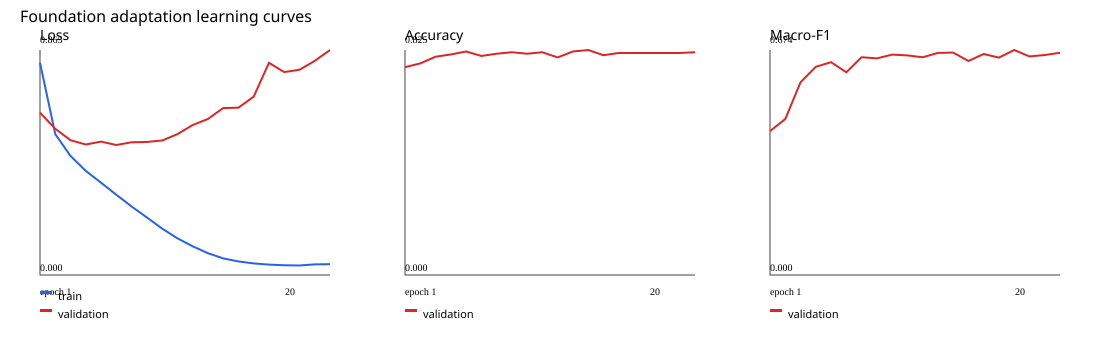

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B0_learning_curves.svg')))

## Interpretation and limits

B0 is the untreated comparison for B1 and B2 on this dataset. Training score coverage is limited by the original log.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})